# HW2. Data Schema Design for ML: Customer Churn Prediction

**Author:** Serhii Kravchenko
**Scenario:** Customer Churn Prediction (domain reference: IBM Telco Customer Churn)
**Environment:** Google Colab (also runs locally on Windows, macOS and Linux), PostgreSQL 16 via `pgserver`, SQL cells via `jupysql`

The notebook is reproducible: every run starts with `DROP TABLE IF EXISTS ... CASCADE`, so **Restart session and run all** works from a clean state.

## 0. Environment

`pgserver` ships PostgreSQL 16 as a Python package, so the database runs inside the notebook session without any extra setup.

A few environment details:
- Colab now defaults to Python 3.13, while `pgserver` 0.1.4 only publishes wheels up to Python 3.12. Its native module is built for the stable ABI (`abi3`), so the 3.12 wheel for the current platform works on 3.13 once the wheel tag is renamed. The install cell handles this automatically.
- The Windows build of `pgserver` comes without the time zone database, so named zones like `'UTC'` fail there. Sessions use `GMT` instead: it is the same zero offset, and PostgreSQL supports it without the database on every platform.
- `XDG_RUNTIME_DIR` is set only to silence a harmless `platformdirs` warning.

In [1]:
import glob, os, subprocess, sys, tempfile

os.environ.setdefault("XDG_RUNTIME_DIR", tempfile.mkdtemp())


def pip_install(*args):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *args])


pip_install("jupysql", "psycopg2-binary", "sqlalchemy", "pandas")

try:
    import pgserver
except ImportError:
    if sys.version_info >= (3, 13):
        tmp = tempfile.mkdtemp()
        subprocess.check_call([
            sys.executable, "-m", "pip", "download", "pgserver==0.1.4",
            "--no-deps", "--only-binary=:all:", "--python-version", "3.12",
            "-d", tmp, "-q",
        ])
        wheel = glob.glob(os.path.join(tmp, "pgserver-*.whl"))[0]
        fixed = wheel.replace("-cp312-cp312-", "-cp312-abi3-")
        os.rename(wheel, fixed)
        pip_install(fixed)
    else:
        pip_install("pgserver==0.1.4")
    import pgserver

print("Python", sys.version.split()[0], "| pgserver ready")

Python 3.11.0 | pgserver ready


In [2]:
from pathlib import Path

PGDATA = Path("/content/pgdata") if Path("/content").exists() else Path.cwd() / "pgdata"
srv = pgserver.get_server(PGDATA)
DB_URI = srv.get_uri()

print(srv.psql("SELECT version();"))

                                                           version                                                            
------------------------------------------------------------------------------------------------------------------------------
 PostgreSQL 16.2 on x86_64-pc-mingw64, compiled by gcc.exe (x86_64-posix-seh-rev2, Built by MinGW-W64 project) 12.2.0, 64-bit
(1 row)




In [3]:
import pandas as pd
from sqlalchemy import create_engine, text

engine = create_engine(
    DB_URI.replace("postgresql://", "postgresql+psycopg2://", 1),
    connect_args={"options": "-c timezone=GMT"},
)


def q(query: str) -> pd.DataFrame:
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)


%load_ext sql
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = 0
%config SqlMagic.displaylimit = 100
%sql engine

In [4]:
%%sql
SELECT current_setting('server_version') AS pg_version,
       current_setting('TimeZone')       AS session_tz;

pg_version,session_tz
16.2,GMT


## 1. ER diagram

A telecom operator wants to predict whether an active customer will churn within the next 30 days. The model is trained on historical prediction points (`prediction_ts`) and served with a single lookup by `customer_id`.

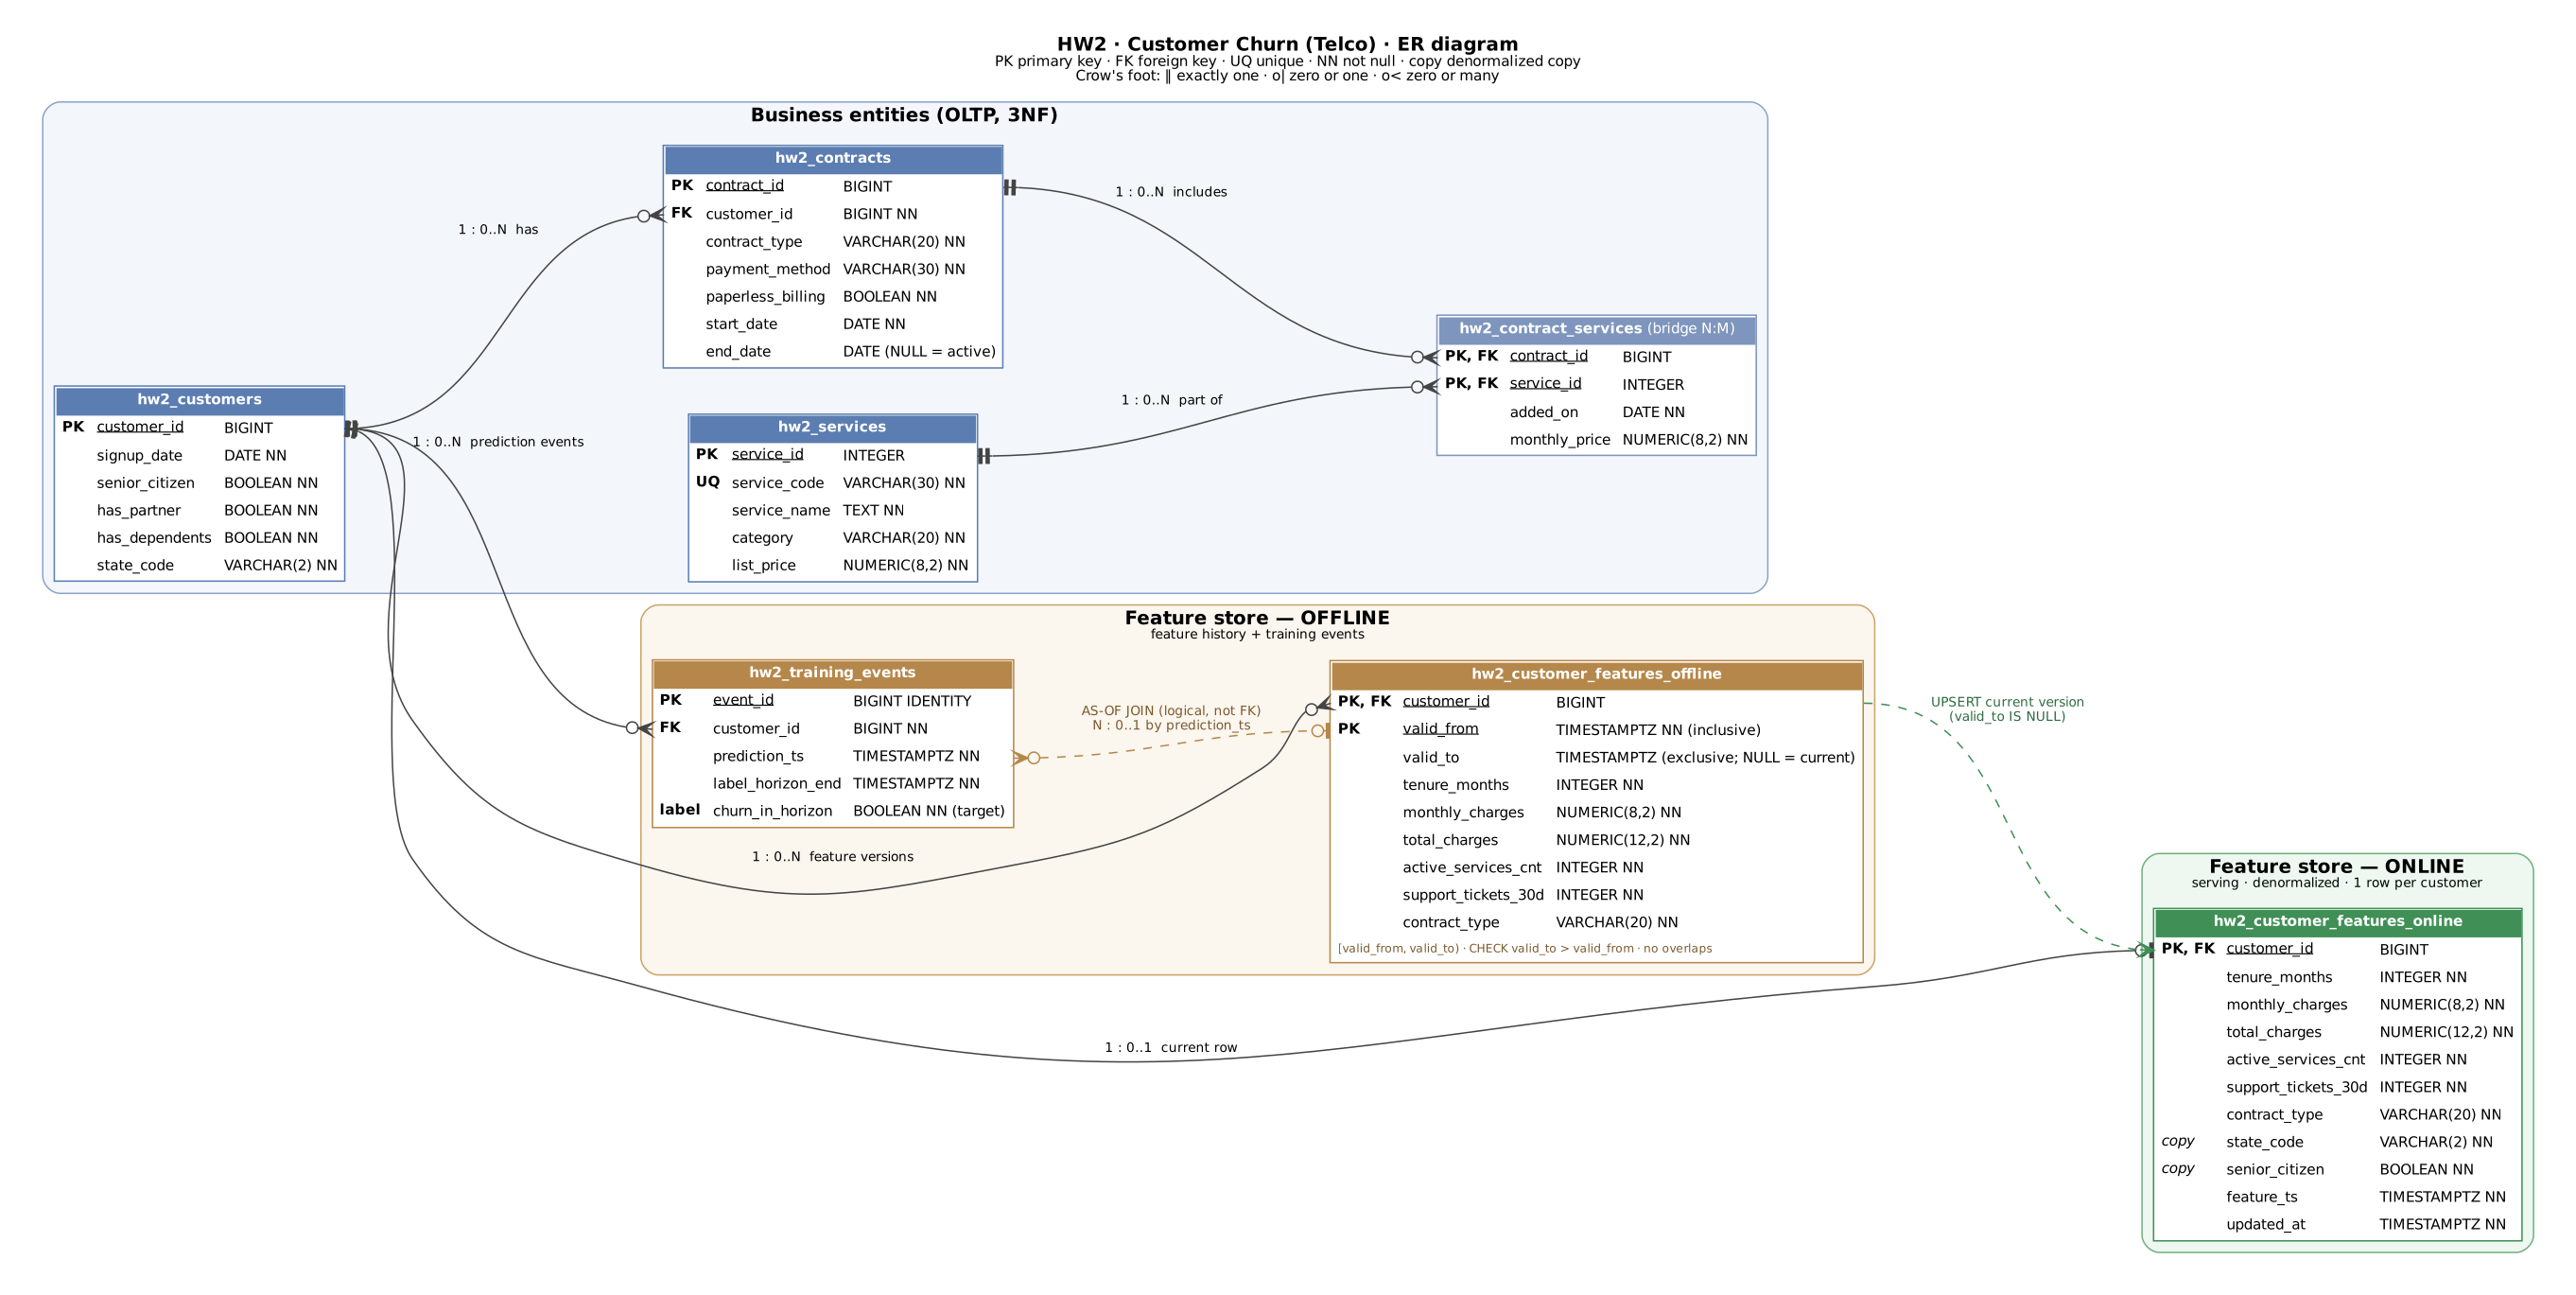

The same schema as text DSL is in `er_diagram.dbml` (it can be pasted into dbdiagram.io).

| Layer | Table | Purpose |
|---|---|---|
| Business | `hw2_customers` | customer profile |
| Business | `hw2_contracts` | customer contracts: type, payment, dates |
| Business | `hw2_services` | service catalog |
| Business | `hw2_contract_services` | bridge table for contracts ↔ services |
| Offline | `hw2_customer_features_offline` | feature history on `[valid_from, valid_to)` |
| Offline | `hw2_training_events` | prediction points and the `churn_in_horizon` label |
| Online | `hw2_customer_features_online` | one denormalized row of current features per customer |

| Relationship | Cardinality | Optionality |
|---|---|---|
| customers → contracts | 1 : 0..N | a contract must have a customer; a customer may have no contracts |
| contracts ↔ services | N : M via bridge | each bridge row must reference both sides |
| customers → features_offline | 1 : 0..N | every version belongs to a customer |
| customers → training_events | 1 : 0..N | every event belongs to a customer |
| customers → features_online | 1 : 0..1 | at most one current row per customer |
| training_events → features_offline | N : 0..1 (logical, not FK) | AS-OF join by `prediction_ts` |

Contracts and services are a natural many-to-many relationship: one contract includes several services and one service is part of many contracts. The price and the date a service was added describe the pair, so they live in the bridge table. I linked services to contracts rather than to customers because the set of services and their prices change together with the contract.

## 2. DDL

Tables are created parent-first, so every foreign key points to a table that already exists.

In [5]:
%%sql
SET TIME ZONE 'GMT';

DROP TABLE IF EXISTS
    hw2_customer_features_online,
    hw2_training_events,
    hw2_customer_features_offline,
    hw2_contract_services,
    hw2_contracts,
    hw2_services,
    hw2_customers
CASCADE;

DROP FUNCTION IF EXISTS hw2_fn_prevent_feature_overlap() CASCADE;

SELECT COUNT(*) AS hw2_tables_left
FROM pg_tables
WHERE tablename LIKE 'hw2\_%';

hw2_tables_left
0


### 2.1 Business entities

In [6]:
%%sql
CREATE TABLE hw2_customers (
    customer_id     BIGINT      PRIMARY KEY,
    signup_date     DATE        NOT NULL,
    senior_citizen  BOOLEAN     NOT NULL DEFAULT FALSE,
    has_partner     BOOLEAN     NOT NULL,
    has_dependents  BOOLEAN     NOT NULL,
    state_code      VARCHAR(2)  NOT NULL
        CHECK (state_code ~ '^[A-Z]{2}$')
);

CREATE TABLE hw2_services (
    service_id    INTEGER       PRIMARY KEY,
    service_code  VARCHAR(30)   NOT NULL UNIQUE,
    service_name  TEXT          NOT NULL,
    category      VARCHAR(20)   NOT NULL
        CHECK (category IN ('phone', 'internet', 'streaming', 'add_on')),
    list_price    NUMERIC(8, 2) NOT NULL
        CHECK (list_price >= 0)
);

CREATE TABLE hw2_contracts (
    contract_id        BIGINT       PRIMARY KEY,
    customer_id        BIGINT       NOT NULL
        REFERENCES hw2_customers (customer_id),
    contract_type      VARCHAR(20)  NOT NULL
        CHECK (contract_type IN ('month_to_month', 'one_year', 'two_year')),
    payment_method     VARCHAR(30)  NOT NULL
        CHECK (payment_method IN ('electronic_check', 'mailed_check',
                                  'bank_transfer', 'credit_card')),
    paperless_billing  BOOLEAN      NOT NULL,
    start_date         DATE         NOT NULL,
    end_date           DATE,

    CHECK (end_date IS NULL OR end_date > start_date)
);

CREATE INDEX hw2_idx_contracts_customer
    ON hw2_contracts (customer_id, start_date DESC);

CREATE TABLE hw2_contract_services (
    contract_id    BIGINT        NOT NULL
        REFERENCES hw2_contracts (contract_id),
    service_id     INTEGER       NOT NULL
        REFERENCES hw2_services (service_id),
    added_on       DATE          NOT NULL,
    monthly_price  NUMERIC(8, 2) NOT NULL
        CHECK (monthly_price >= 0),

    PRIMARY KEY (contract_id, service_id)
);

CREATE INDEX hw2_idx_contract_services_service
    ON hw2_contract_services (service_id);

SELECT tablename
FROM pg_tables
WHERE tablename LIKE 'hw2\_%'
ORDER BY tablename;

tablename
hw2_contract_services
hw2_contracts
hw2_customers
hw2_services


### 2.2 Offline feature store

Feature versions follow SCD Type 2: each version is valid on `[valid_from, valid_to)`, and `valid_to IS NULL` marks the current one. The index on `(customer_id, valid_from DESC)` serves the main access pattern, "the latest version that started at or before time T". The partial unique index allows only one current version per customer.

In [7]:
%%sql
CREATE TABLE hw2_customer_features_offline (
    customer_id          BIGINT         NOT NULL
        REFERENCES hw2_customers (customer_id),
    valid_from           TIMESTAMPTZ    NOT NULL,
    valid_to             TIMESTAMPTZ,
    tenure_months        INTEGER        NOT NULL
        CHECK (tenure_months >= 0),
    monthly_charges      NUMERIC(8, 2)  NOT NULL
        CHECK (monthly_charges >= 0),
    total_charges        NUMERIC(12, 2) NOT NULL
        CHECK (total_charges >= 0),
    active_services_cnt  INTEGER        NOT NULL
        CHECK (active_services_cnt BETWEEN 0 AND 20),
    support_tickets_30d  INTEGER        NOT NULL
        CHECK (support_tickets_30d >= 0),
    contract_type        VARCHAR(20)    NOT NULL
        CHECK (contract_type IN ('month_to_month', 'one_year', 'two_year')),

    PRIMARY KEY (customer_id, valid_from),

    CHECK (
        valid_to IS NULL
        OR valid_to > valid_from
    )
);

CREATE INDEX hw2_idx_cust_feat_asof
    ON hw2_customer_features_offline (customer_id, valid_from DESC);

CREATE UNIQUE INDEX hw2_uq_cust_feat_current
    ON hw2_customer_features_offline (customer_id)
    WHERE valid_to IS NULL;

CREATE TABLE hw2_training_events (
    event_id           BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,
    customer_id        BIGINT       NOT NULL
        REFERENCES hw2_customers (customer_id),
    prediction_ts      TIMESTAMPTZ  NOT NULL,
    label_horizon_end  TIMESTAMPTZ  NOT NULL,
    churn_in_horizon   BOOLEAN      NOT NULL,

    UNIQUE (customer_id, prediction_ts),
    CHECK (label_horizon_end > prediction_ts)
);

SELECT tablename
FROM pg_tables
WHERE tablename LIKE 'hw2\_%'
ORDER BY tablename;

tablename
hw2_contract_services
hw2_contracts
hw2_customer_features_offline
hw2_customers
hw2_services
hw2_training_events


### 2.3 Online feature store

One row per customer with current values only, plus copies of `state_code` and `senior_citizen`, so serving doesn't need a join.

In [8]:
%%sql
CREATE TABLE hw2_customer_features_online (
    customer_id          BIGINT         PRIMARY KEY
        REFERENCES hw2_customers (customer_id),
    tenure_months        INTEGER        NOT NULL
        CHECK (tenure_months >= 0),
    monthly_charges      NUMERIC(8, 2)  NOT NULL
        CHECK (monthly_charges >= 0),
    total_charges        NUMERIC(12, 2) NOT NULL
        CHECK (total_charges >= 0),
    active_services_cnt  INTEGER        NOT NULL
        CHECK (active_services_cnt BETWEEN 0 AND 20),
    support_tickets_30d  INTEGER        NOT NULL
        CHECK (support_tickets_30d >= 0),
    contract_type        VARCHAR(20)    NOT NULL
        CHECK (contract_type IN ('month_to_month', 'one_year', 'two_year')),
    state_code           VARCHAR(2)     NOT NULL,
    senior_citizen       BOOLEAN        NOT NULL,
    feature_ts           TIMESTAMPTZ    NOT NULL,
    updated_at           TIMESTAMPTZ    NOT NULL
        DEFAULT CURRENT_TIMESTAMP
);

SELECT tablename
FROM pg_tables
WHERE tablename LIKE 'hw2\_%'
ORDER BY tablename;

tablename
hw2_contract_services
hw2_contracts
hw2_customer_features_offline
hw2_customer_features_online
hw2_customers
hw2_services
hw2_training_events


### 2.4 Preventing overlapping versions

A `CHECK` only sees one row, so it can't catch overlaps between versions of the same customer. Usually this is done with `EXCLUDE USING gist`, but the `btree_gist` extension isn't available in `pgserver`, so a trigger does the same job. Invalid intervals are left to the `CHECK` constraint.

In [9]:
%%sql
CREATE FUNCTION hw2_fn_prevent_feature_overlap()
RETURNS trigger
LANGUAGE plpgsql
AS $$
BEGIN
    IF NEW.valid_to IS NOT NULL AND NEW.valid_to <= NEW.valid_from THEN
        RETURN NEW;
    END IF;

    IF EXISTS (
        SELECT 1
        FROM hw2_customer_features_offline AS o
        WHERE o.customer_id = NEW.customer_id
          AND NOT (TG_OP = 'UPDATE'
                   AND o.customer_id = OLD.customer_id
                   AND o.valid_from  = OLD.valid_from)
          AND o.valid_from  < COALESCE(NEW.valid_to, 'infinity'::timestamptz)
          AND NEW.valid_from < COALESCE(o.valid_to, 'infinity'::timestamptz)
    ) THEN
        RAISE EXCEPTION
            'Overlapping feature version for customer_id=% at [%, %)',
            NEW.customer_id, NEW.valid_from, NEW.valid_to;
    END IF;

    RETURN NEW;
END;
$$;

CREATE TRIGGER hw2_trg_prevent_feature_overlap
    BEFORE INSERT OR UPDATE ON hw2_customer_features_offline
    FOR EACH ROW
    EXECUTE FUNCTION hw2_fn_prevent_feature_overlap();

SELECT tgname AS trigger_name, tgrelid::regclass AS table_name
FROM pg_trigger
WHERE tgname = 'hw2_trg_prevent_feature_overlap';

trigger_name,table_name
hw2_trg_prevent_feature_overlap,hw2_customer_features_offline


Constraints and indexes that were created:

In [10]:
%%sql
SELECT tc.table_name,
       COUNT(*) FILTER (WHERE tc.constraint_type = 'PRIMARY KEY') AS pk,
       COUNT(*) FILTER (WHERE tc.constraint_type = 'FOREIGN KEY') AS fk,
       COUNT(*) FILTER (WHERE tc.constraint_type = 'UNIQUE')      AS uq,
       COUNT(*) FILTER (WHERE tc.constraint_type = 'CHECK'
                          AND tc.constraint_name NOT LIKE '%_not_null') AS checks
FROM information_schema.table_constraints AS tc
WHERE tc.table_name LIKE 'hw2\_%'
GROUP BY tc.table_name
ORDER BY tc.table_name;

table_name,pk,fk,uq,checks
hw2_contract_services,1,2,0,1
hw2_contracts,1,1,0,3
hw2_customer_features_offline,1,1,0,7
hw2_customer_features_online,1,1,0,6
hw2_customers,1,0,0,1
hw2_services,1,0,1,2
hw2_training_events,1,1,1,1


In [11]:
%%sql
SELECT tablename, indexname
FROM pg_indexes
WHERE tablename LIKE 'hw2\_%'
ORDER BY tablename, indexname;

tablename,indexname
hw2_contract_services,hw2_contract_services_pkey
hw2_contract_services,hw2_idx_contract_services_service
hw2_contracts,hw2_contracts_pkey
hw2_contracts,hw2_idx_contracts_customer
hw2_customer_features_offline,hw2_customer_features_offline_pkey
hw2_customer_features_offline,hw2_idx_cust_feat_asof
hw2_customer_features_offline,hw2_uq_cust_feat_current
hw2_customer_features_online,hw2_customer_features_online_pkey
hw2_customers,hw2_customers_pkey
hw2_services,hw2_services_pkey


## 3. Normalization

`hw2_customers`, `hw2_services`, `hw2_contracts` and `hw2_contract_services` are in 3NF: values are atomic, there are no partial dependencies on composite keys, and no non-key attribute depends on another non-key attribute.

Functional dependencies I used for the decomposition:
- `customer_id → signup_date, senior_citizen, has_partner, has_dependents, state_code`
- `contract_id → customer_id, contract_type, payment_method, paperless_billing, start_date, end_date`
- `service_id → service_code, service_name, category, list_price`, and `service_code → service_id`
- `(contract_id, service_id) → added_on, monthly_price`

The contract price of a service depends on the whole composite key, so it is stored in the bridge table, while `hw2_services` only keeps the list price. Customer attributes are not repeated in contracts, which avoids the transitive dependency `contract_id → customer_id → state_code`.

`hw2_customer_features_online` is intentionally denormalized. It keeps only the current feature version and copies `state_code` and `senior_citizen` from `hw2_customers`. The read pattern is a lookup by `customer_id` at inference time: one row by primary key, no joins and no interval conditions, which keeps latency low and predictable.

The risk is that the copies drift from the source, for example when a customer moves to another state or a new offline version hasn't been pushed yet. The online table is refreshed by a batch upsert from offline rows with `valid_to IS NULL`, and a consistency check after the refresh should return zero rows (section 4.6).

## 4. Point-in-time correctness

### 4.1 Test data

A small controlled dataset based on Telco attributes: 4 customers, 12 feature versions and 9 training events. All timestamps are `TIMESTAMPTZ` literals with an explicit `+00`.

- Customer 42 has four consecutive versions: streaming is added on Feb 25 and support tickets keep growing.
- Customer 1 switches from month-to-month to a one-year contract on Jan 10.
- Customer 2 churns on Apr 10, so the last version is closed and there is no current one.
- Customer 7 is a stable two-year customer. One of their events (Dec 15, 2024) happens before the first feature version.

Event 2 is placed exactly on a version boundary (2025-03-01 00:00 UTC) to test the half-open interval.

In [12]:
%%sql
INSERT INTO hw2_customers
    (customer_id, signup_date, senior_citizen, has_partner, has_dependents, state_code)
VALUES
    (1,  DATE '2024-01-10', FALSE, TRUE,  FALSE, 'CA'),
    (2,  DATE '2024-02-20', TRUE,  FALSE, FALSE, 'CA'),
    (7,  DATE '2024-06-01', FALSE, TRUE,  TRUE,  'TX'),
    (42, DATE '2024-03-15', FALSE, FALSE, FALSE, 'NV');

INSERT INTO hw2_services
    (service_id, service_code, service_name, category, list_price)
VALUES
    (1, 'PHONE',           'Phone line',           'phone',     25.00),
    (2, 'FIBER_INTERNET',  'Fiber optic internet', 'internet',  50.00),
    (3, 'DSL_INTERNET',    'DSL internet',         'internet',  30.00),
    (4, 'STREAMING_TV',    'Streaming TV',         'streaming', 19.90),
    (5, 'TECH_SUPPORT',    'Tech support',         'add_on',    20.00),
    (6, 'ONLINE_SECURITY', 'Online security',      'add_on',    15.00);

INSERT INTO hw2_contracts
    (contract_id, customer_id, contract_type, payment_method,
     paperless_billing, start_date, end_date)
VALUES
    (101,  1,  'month_to_month', 'mailed_check',     FALSE, DATE '2024-01-10', DATE '2025-01-10'),
    (102,  1,  'one_year',       'bank_transfer',    TRUE,  DATE '2025-01-10', NULL),
    (201,  2,  'month_to_month', 'electronic_check', TRUE,  DATE '2024-02-20', DATE '2025-04-10'),
    (701,  7,  'two_year',       'credit_card',      TRUE,  DATE '2024-06-01', NULL),
    (4201, 42, 'month_to_month', 'electronic_check', TRUE,  DATE '2024-03-15', NULL);

INSERT INTO hw2_contract_services
    (contract_id, service_id, added_on, monthly_price)
VALUES
    (101,  1, DATE '2024-01-10', 25.00),
    (101,  3, DATE '2024-01-10', 30.00),
    (102,  1, DATE '2025-01-10', 22.00),
    (102,  3, DATE '2025-01-10', 28.00),
    (201,  1, DATE '2024-02-20', 25.00),
    (201,  2, DATE '2024-02-20', 50.00),
    (201,  5, DATE '2024-02-20', 20.00),
    (701,  1, DATE '2024-06-01', 25.00),
    (701,  2, DATE '2024-06-01', 50.00),
    (701,  4, DATE '2024-06-01', 15.00),
    (701,  6, DATE '2024-06-01', 15.00),
    (4201, 1, DATE '2024-03-15', 20.00),
    (4201, 3, DATE '2024-03-15', 50.00),
    (4201, 4, DATE '2025-02-25', 19.90);

SELECT 'hw2_customers' AS table_name, COUNT(*) AS rows FROM hw2_customers
UNION ALL SELECT 'hw2_services', COUNT(*) FROM hw2_services
UNION ALL SELECT 'hw2_contracts', COUNT(*) FROM hw2_contracts
UNION ALL SELECT 'hw2_contract_services', COUNT(*) FROM hw2_contract_services;

table_name,rows
hw2_customers,4
hw2_services,6
hw2_contracts,5
hw2_contract_services,14


In [13]:
%%sql
INSERT INTO hw2_customer_features_offline
    (customer_id, valid_from, valid_to,
     tenure_months, monthly_charges, total_charges,
     active_services_cnt, support_tickets_30d, contract_type)
VALUES
    (42, TIMESTAMPTZ '2025-01-01 00:00:00+00', TIMESTAMPTZ '2025-02-01 00:00:00+00',  9,  70.00,  630.00, 2, 0, 'month_to_month'),
    (42, TIMESTAMPTZ '2025-02-01 00:00:00+00', TIMESTAMPTZ '2025-03-01 00:00:00+00', 10,  70.00,  700.00, 2, 1, 'month_to_month'),
    (42, TIMESTAMPTZ '2025-03-01 00:00:00+00', TIMESTAMPTZ '2025-03-15 00:00:00+00', 11,  89.90,  789.90, 3, 3, 'month_to_month'),
    (42, TIMESTAMPTZ '2025-03-15 00:00:00+00', NULL,                                 12,  89.90,  879.80, 3, 4, 'month_to_month'),

    (1,  TIMESTAMPTZ '2025-01-01 00:00:00+00', TIMESTAMPTZ '2025-01-10 00:00:00+00', 11,  55.00,  605.00, 2, 0, 'month_to_month'),
    (1,  TIMESTAMPTZ '2025-01-10 00:00:00+00', TIMESTAMPTZ '2025-03-01 00:00:00+00', 12,  50.00,  655.00, 2, 0, 'one_year'),
    (1,  TIMESTAMPTZ '2025-03-01 00:00:00+00', NULL,                                 13,  50.00,  705.00, 2, 1, 'one_year'),

    (2,  TIMESTAMPTZ '2025-01-01 00:00:00+00', TIMESTAMPTZ '2025-02-15 00:00:00+00', 10,  95.00,  950.00, 3, 1, 'month_to_month'),
    (2,  TIMESTAMPTZ '2025-02-15 00:00:00+00', TIMESTAMPTZ '2025-03-20 00:00:00+00', 11,  95.00, 1045.00, 3, 4, 'month_to_month'),
    (2,  TIMESTAMPTZ '2025-03-20 00:00:00+00', TIMESTAMPTZ '2025-04-10 00:00:00+00', 12,  95.00, 1140.00, 3, 6, 'month_to_month'),

    (7,  TIMESTAMPTZ '2025-01-01 00:00:00+00', TIMESTAMPTZ '2025-02-01 00:00:00+00',  7, 105.00,  735.00, 4, 0, 'two_year'),
    (7,  TIMESTAMPTZ '2025-02-01 00:00:00+00', NULL,                                  8, 105.00,  840.00, 4, 0, 'two_year');

SELECT customer_id,
       COUNT(*)                                 AS versions,
       COUNT(*) FILTER (WHERE valid_to IS NULL) AS current_versions
FROM hw2_customer_features_offline
GROUP BY customer_id
ORDER BY versions DESC, customer_id;

customer_id,versions,current_versions
42,4,1
1,3,1
2,3,0
7,2,1


In [14]:
%%sql
INSERT INTO hw2_training_events
    (customer_id, prediction_ts, label_horizon_end, churn_in_horizon)
VALUES
    (42, TIMESTAMPTZ '2025-01-20 10:00:00+00', TIMESTAMPTZ '2025-02-19 10:00:00+00', FALSE),
    (42, TIMESTAMPTZ '2025-03-01 00:00:00+00', TIMESTAMPTZ '2025-03-31 00:00:00+00', FALSE),
    (42, TIMESTAMPTZ '2025-03-20 10:00:00+00', TIMESTAMPTZ '2025-04-19 10:00:00+00', FALSE),
    (1,  TIMESTAMPTZ '2025-01-05 12:00:00+00', TIMESTAMPTZ '2025-02-04 12:00:00+00', FALSE),
    (1,  TIMESTAMPTZ '2025-02-15 09:00:00+00', TIMESTAMPTZ '2025-03-17 09:00:00+00', FALSE),
    (2,  TIMESTAMPTZ '2025-02-01 08:00:00+00', TIMESTAMPTZ '2025-03-03 08:00:00+00', FALSE),
    (2,  TIMESTAMPTZ '2025-03-25 08:00:00+00', TIMESTAMPTZ '2025-04-24 08:00:00+00', TRUE),
    (7,  TIMESTAMPTZ '2025-02-10 10:00:00+00', TIMESTAMPTZ '2025-03-12 10:00:00+00', FALSE),
    (7,  TIMESTAMPTZ '2024-12-15 10:00:00+00', TIMESTAMPTZ '2025-01-14 10:00:00+00', FALSE);

SELECT COUNT(*) AS training_events
FROM hw2_training_events;

training_events
9


### 4.2 AS-OF queries

**Query 1.** Customer 42 as of 2025-02-15 10:00 UTC. Expected: the version that started on 2025-02-01.

In [15]:
%%sql
SELECT customer_id, valid_from, valid_to,
       tenure_months, monthly_charges, active_services_cnt,
       support_tickets_30d, contract_type
FROM hw2_customer_features_offline
WHERE customer_id = 42
  AND valid_from <= TIMESTAMPTZ '2025-02-15 10:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2025-02-15 10:00:00+00'
        OR valid_to IS NULL
      );

customer_id,valid_from,valid_to,tenure_months,monthly_charges,active_services_cnt,support_tickets_30d,contract_type
42,2025-02-01 00:00:00+00:00,2025-03-01 00:00:00+00:00,10,70.00,2,1,month_to_month


**Query 2.** Customer 42 as of 2025-03-01 00:00 UTC, which is both the end of one version and the start of the next. Because the interval is half-open, exactly one row comes back: the new version.

In [16]:
%%sql
SELECT customer_id, valid_from, valid_to,
       tenure_months, monthly_charges, active_services_cnt,
       support_tickets_30d
FROM hw2_customer_features_offline
WHERE customer_id = 42
  AND valid_from <= TIMESTAMPTZ '2025-03-01 00:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2025-03-01 00:00:00+00'
        OR valid_to IS NULL
      );

customer_id,valid_from,valid_to,tenure_months,monthly_charges,active_services_cnt,support_tickets_30d
42,2025-03-01 00:00:00+00:00,2025-03-15 00:00:00+00:00,11,89.90,3,3


**Query 3.** Snapshot of all customers as of 2025-03-10 00:00 UTC, one valid version per customer.

In [17]:
%%sql
SELECT customer_id, valid_from, valid_to,
       tenure_months, monthly_charges, support_tickets_30d, contract_type
FROM hw2_customer_features_offline
WHERE valid_from <= TIMESTAMPTZ '2025-03-10 00:00:00+00'
  AND (
        valid_to > TIMESTAMPTZ '2025-03-10 00:00:00+00'
        OR valid_to IS NULL
      )
ORDER BY customer_id;

customer_id,valid_from,valid_to,tenure_months,monthly_charges,support_tickets_30d,contract_type
1,2025-03-01 00:00:00+00:00,None,13,50.00,1,one_year
2,2025-02-15 00:00:00+00:00,2025-03-20 00:00:00+00:00,11,95.00,4,month_to_month
7,2025-02-01 00:00:00+00:00,None,8,105.00,0,two_year
42,2025-03-01 00:00:00+00:00,2025-03-15 00:00:00+00:00,11,89.90,3,month_to_month


### 4.3 AS-OF join for training data

Each training event gets only the feature version that was valid at `prediction_ts`. `LEFT JOIN` keeps events that have no features yet: customer 7's event from 2024-12-15 gets NULLs (cold start).

In [18]:
%%sql
SELECT
    e.event_id,
    e.customer_id,
    e.prediction_ts,
    e.label_horizon_end,
    e.churn_in_horizon,
    f.valid_from AS feature_valid_from,
    f.tenure_months,
    f.monthly_charges,
    f.total_charges,
    f.active_services_cnt,
    f.support_tickets_30d,
    f.contract_type
FROM hw2_training_events AS e
LEFT JOIN hw2_customer_features_offline AS f
    ON  f.customer_id = e.customer_id
    AND f.valid_from <= e.prediction_ts
    AND (
            f.valid_to > e.prediction_ts
            OR f.valid_to IS NULL
        )
ORDER BY e.event_id;

event_id,customer_id,prediction_ts,label_horizon_end,churn_in_horizon,feature_valid_from,tenure_months,monthly_charges,total_charges,active_services_cnt,support_tickets_30d,contract_type
1,42,2025-01-20 10:00:00+00:00,2025-02-19 10:00:00+00:00,False,2025-01-01 00:00:00+00:00,9,70.00,630.00,2,0,month_to_month
2,42,2025-03-01 00:00:00+00:00,2025-03-31 00:00:00+00:00,False,2025-03-01 00:00:00+00:00,11,89.90,789.90,3,3,month_to_month
3,42,2025-03-20 10:00:00+00:00,2025-04-19 10:00:00+00:00,False,2025-03-15 00:00:00+00:00,12,89.90,879.80,3,4,month_to_month
4,1,2025-01-05 12:00:00+00:00,2025-02-04 12:00:00+00:00,False,2025-01-01 00:00:00+00:00,11,55.00,605.00,2,0,month_to_month
5,1,2025-02-15 09:00:00+00:00,2025-03-17 09:00:00+00:00,False,2025-01-10 00:00:00+00:00,12,50.00,655.00,2,0,one_year
6,2,2025-02-01 08:00:00+00:00,2025-03-03 08:00:00+00:00,False,2025-01-01 00:00:00+00:00,10,95.00,950.00,3,1,month_to_month
7,2,2025-03-25 08:00:00+00:00,2025-04-24 08:00:00+00:00,True,2025-03-20 00:00:00+00:00,12,95.00,1140.00,3,6,month_to_month
8,7,2025-02-10 10:00:00+00:00,2025-03-12 10:00:00+00:00,False,2025-02-01 00:00:00+00:00,8,105.00,840.00,4,0,two_year
9,7,2024-12-15 10:00:00+00:00,2025-01-14 10:00:00+00:00,False,None,None,None,None,None,None,None


### 4.4 Why a plain join on `customer_id` is wrong

In [19]:
%%sql
SELECT
    COUNT(DISTINCT e.event_id)                             AS events,
    COUNT(*)                                               AS rows_after_naive_join,
    COUNT(*) FILTER (WHERE f.valid_from > e.prediction_ts) AS rows_with_future_features
FROM hw2_training_events AS e
JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id;

events,rows_after_naive_join,rows_with_future_features
9,28,11


In [20]:
%%sql
SELECT e.event_id, e.prediction_ts, e.churn_in_horizon,
       f.valid_from, f.support_tickets_30d,
       f.valid_from > e.prediction_ts AS is_from_future
FROM hw2_training_events AS e
JOIN hw2_customer_features_offline AS f
    ON f.customer_id = e.customer_id
WHERE e.customer_id = 2
  AND e.prediction_ts = TIMESTAMPTZ '2025-02-01 08:00:00+00'
ORDER BY f.valid_from;

event_id,prediction_ts,churn_in_horizon,valid_from,support_tickets_30d,is_from_future
6,2025-02-01 08:00:00+00:00,False,2025-01-01 00:00:00+00:00,1,False
6,2025-02-01 08:00:00+00:00,False,2025-02-15 00:00:00+00:00,4,True
6,2025-02-01 08:00:00+00:00,False,2025-03-20 00:00:00+00:00,6,True


A plain join attaches every version to every event: 9 events turn into 28 rows, and 11 of them contain features from after the prediction time. For customer 2's event on Feb 1, the model would also see 4 and 6 support tickets, which only happened weeks later, right before the churn. That is data leakage: duplicated examples and inflated train/validation metrics that won't hold up in production.

About the AS-OF conditions:

1. `valid_from <= prediction_ts` means the version already existed. It is inclusive because a version is valid from its first moment.
2. `valid_to > prediction_ts OR valid_to IS NULL` means the version hadn't ended yet. It is strict because at `valid_to` the next version takes over. The `IS NULL` branch is needed because a comparison with NULL returns NULL, so current versions would be lost without it.
3. With half-open intervals `[valid_from, valid_to)`, neighbouring versions touch without gaps or overlaps, and every moment belongs to exactly one version. A closed interval would put the boundary in two versions (see query 2), an open one in none.
4. Without the time filter, later values leak in: the streaming service in customer 42's January event, the one-year contract in customer 1's Jan 5 event, and customer 2's growing ticket count before the churn.

### 4.5 Interval checks

Overlapping intervals. This must return 0 rows.

In [21]:
%%sql
SELECT
    a.customer_id,
    a.valid_from AS a_from,
    a.valid_to   AS a_to,
    b.valid_from AS b_from,
    b.valid_to   AS b_to
FROM hw2_customer_features_offline AS a
JOIN hw2_customer_features_offline AS b
  ON a.customer_id = b.customer_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;

customer_id,a_from,a_to,b_from,b_to


Gaps between consecutive versions. This must also return 0 rows.

In [22]:
%%sql
SELECT customer_id, valid_from, valid_to, next_from
FROM (
    SELECT customer_id, valid_from, valid_to,
           LEAD(valid_from) OVER (PARTITION BY customer_id ORDER BY valid_from) AS next_from
    FROM hw2_customer_features_offline
) AS t
WHERE next_from IS NOT NULL
  AND valid_to IS DISTINCT FROM next_from;

customer_id,valid_from,valid_to,next_from


Both constraints in action: the trigger rejects an overlapping version, and the `CHECK` rejects `valid_to <= valid_from`.

In [23]:
from sqlalchemy.exc import DBAPIError

bad_rows = {
    "overlapping version": """
        INSERT INTO hw2_customer_features_offline
            (customer_id, valid_from, valid_to, tenure_months, monthly_charges,
             total_charges, active_services_cnt, support_tickets_30d, contract_type)
        VALUES (42, TIMESTAMPTZ '2025-02-10 00:00:00+00', TIMESTAMPTZ '2025-02-20 00:00:00+00',
                10, 70.00, 700.00, 2, 1, 'month_to_month')""",
    "valid_to <= valid_from": """
        INSERT INTO hw2_customer_features_offline
            (customer_id, valid_from, valid_to, tenure_months, monthly_charges,
             total_charges, active_services_cnt, support_tickets_30d, contract_type)
        VALUES (7, TIMESTAMPTZ '2026-01-01 00:00:00+00', TIMESTAMPTZ '2025-12-31 00:00:00+00',
                9, 105.00, 945.00, 4, 0, 'two_year')""",
}

for case, stmt in bad_rows.items():
    try:
        with engine.begin() as conn:
            conn.execute(text(stmt))
    except DBAPIError as err:
        print(f"Rejected as expected ({case}): {err.orig.diag.message_primary}")
    else:
        raise AssertionError(f"Invalid row was accepted: {case}")

Rejected as expected (overlapping version): Overlapping feature version for customer_id=42 at [2025-02-10 00:00:00+00, 2025-02-20 00:00:00+00)
Rejected as expected (valid_to <= valid_from): new row for relation "hw2_customer_features_offline" violates check constraint "hw2_customer_features_offline_check"


### 4.6 Online store refresh

The online table is refreshed with an idempotent upsert from the current offline versions. Customers without a current version (customer 2) are removed.

In [24]:
%%sql
INSERT INTO hw2_customer_features_online AS o
    (customer_id, tenure_months, monthly_charges, total_charges,
     active_services_cnt, support_tickets_30d, contract_type,
     state_code, senior_citizen, feature_ts, updated_at)
SELECT f.customer_id, f.tenure_months, f.monthly_charges, f.total_charges,
       f.active_services_cnt, f.support_tickets_30d, f.contract_type,
       c.state_code, c.senior_citizen, f.valid_from, CURRENT_TIMESTAMP
FROM hw2_customer_features_offline AS f
JOIN hw2_customers AS c USING (customer_id)
WHERE f.valid_to IS NULL
ON CONFLICT (customer_id) DO UPDATE
SET tenure_months       = EXCLUDED.tenure_months,
    monthly_charges     = EXCLUDED.monthly_charges,
    total_charges       = EXCLUDED.total_charges,
    active_services_cnt = EXCLUDED.active_services_cnt,
    support_tickets_30d = EXCLUDED.support_tickets_30d,
    contract_type       = EXCLUDED.contract_type,
    state_code          = EXCLUDED.state_code,
    senior_citizen      = EXCLUDED.senior_citizen,
    feature_ts          = EXCLUDED.feature_ts,
    updated_at          = EXCLUDED.updated_at
WHERE o.feature_ts < EXCLUDED.feature_ts
   OR o.state_code     IS DISTINCT FROM EXCLUDED.state_code
   OR o.senior_citizen IS DISTINCT FROM EXCLUDED.senior_citizen;

DELETE FROM hw2_customer_features_online AS o
WHERE NOT EXISTS (
    SELECT 1
    FROM hw2_customer_features_offline AS f
    WHERE f.customer_id = o.customer_id
      AND f.valid_to IS NULL
);

SELECT COUNT(*) AS online_rows
FROM hw2_customer_features_online;

online_rows
3


Serving lookup: one row by primary key.

In [25]:
%%sql
SELECT *
FROM hw2_customer_features_online
WHERE customer_id = 42;

customer_id,tenure_months,monthly_charges,total_charges,active_services_cnt,support_tickets_30d,contract_type,state_code,senior_citizen,feature_ts,updated_at
42,12,89.90,879.80,3,4,month_to_month,NV,False,2025-03-15 00:00:00+00:00,2026-11-04 08:29:09.296202+00:00


Consistency between online and offline. This must return 0 rows.

In [26]:
%%sql
SELECT COALESCE(o.customer_id, f.customer_id) AS customer_id,
       o.feature_ts, f.valid_from
FROM hw2_customer_features_online AS o
FULL JOIN (
    SELECT f.*, c.state_code, c.senior_citizen
    FROM hw2_customer_features_offline AS f
    JOIN hw2_customers AS c USING (customer_id)
    WHERE f.valid_to IS NULL
) AS f
    ON f.customer_id = o.customer_id
WHERE o.customer_id IS NULL
   OR f.customer_id IS NULL
   OR (o.tenure_months, o.monthly_charges, o.total_charges, o.active_services_cnt,
       o.support_tickets_30d, o.contract_type, o.state_code, o.senior_citizen, o.feature_ts)
      IS DISTINCT FROM
      (f.tenure_months, f.monthly_charges, f.total_charges, f.active_services_cnt,
       f.support_tickets_30d, f.contract_type, f.state_code, f.senior_citizen, f.valid_from);

customer_id,feature_ts,valid_from


## 5. Reflection

**What was the hardest part?** Point-in-time correctness. The SQL condition is short, but the data has to be consistent: each `valid_to` must match the next `valid_from`, an event on a boundary must land in one version, and a churned customer's last version has to be closed. I also had to decide whether services belong to customers or to contracts, and chose contracts because prices and service sets change together with the contract.

**Trade-offs.** The business tables are in 3NF, so every fact is stored once. The offline table stores feature snapshots instead of computing them on the fly, so training data can be rebuilt exactly as it was. The online table is denormalized on purpose: reads happen on every prediction and writes once a day, so it's cheaper to join once on write.

**Scaling the online layer.** I would move serving to a key-value store such as Redis or DynamoDB, keyed by `customer_id` with a precomputed feature vector, sharded by key and cached in the application. Freshness would be tracked through `feature_ts`, a TTL and monitoring of the offline-to-online lag. Fast-changing features like `support_tickets_30d` could be updated by streaming.

**Schema evolution risks over six months.** Renaming a feature breaks older models, so I would add a new column and keep the old name through a view for a transition period. A type change, for example `INTEGER` to `NUMERIC`, needs a new feature version with an explicit cast. A change in meaning is the most dangerous because it is silent, so it should get a new name or a `feature_version` and a registry of feature definitions. Columns should be removed only after a deprecation period, and older model versions need their own feature views and saved AS-OF parameters to rebuild their training sets.

## 6. Final checks

In [27]:
tables = set(q("SELECT tablename FROM pg_tables WHERE tablename LIKE 'hw2\\_%'")["tablename"])
constraints = q("""
    SELECT constraint_type, COUNT(*) AS n, COUNT(DISTINCT table_name) AS tables
    FROM information_schema.table_constraints
    WHERE table_name LIKE 'hw2\\_%'
    GROUP BY constraint_type
""").set_index("constraint_type")
history = q("SELECT customer_id, COUNT(*) AS versions FROM hw2_customer_features_offline GROUP BY customer_id")
training = q("""
    SELECT e.event_id, e.prediction_ts, f.valid_from
    FROM hw2_training_events AS e
    LEFT JOIN hw2_customer_features_offline AS f
        ON  f.customer_id = e.customer_id
        AND f.valid_from <= e.prediction_ts
        AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
""")
overlaps = q("""
    SELECT 1
    FROM hw2_customer_features_offline AS a
    JOIN hw2_customer_features_offline AS b
      ON a.customer_id = b.customer_id
     AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
     AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
     AND a.valid_from < b.valid_from
""")
matched = training.dropna(subset=["valid_from"])

assert q("SELECT EXTRACT(TIMEZONE FROM now()) AS offset_s")["offset_s"][0] == 0
assert len(tables) == 7
assert constraints.loc["PRIMARY KEY", "tables"] == len(tables)
assert constraints.loc["FOREIGN KEY", "n"] == 6
assert "hw2_idx_cust_feat_asof" in set(q("SELECT indexname FROM pg_indexes")["indexname"])
assert history["versions"].sum() >= 10
assert len(history) >= 3
assert history["versions"].max() >= 3
assert len(overlaps) == 0
assert training["event_id"].is_unique
assert len(training) == q("SELECT COUNT(*) AS n FROM hw2_training_events")["n"][0]
assert (matched["valid_from"] <= matched["prediction_ts"]).all()

print("All checks passed")

All checks passed
